# EDA: Salud mental en el sector tecnológico

## 1. Introducción

Este proyecto analiza la encuesta «Mental Health in Tech Survey» de OSMI, realizada entre 2014 y 2016 a personas que trabajan en el sector tecnológico. El dataset (data/survey.csv) tiene 1259 respuestas y 27 columnas: cada fila es una persona y cada columna es una pregunta de la encuesta.
El objetivo es entender quién busca tratamiento para su salud mental y qué factores influyen. La variable principal es treatment (si la persona ha buscado tratamiento alguna vez).
El notebook sigue este orden: primer vistazo a los datos, detección de problemas de calidad, limpieza, análisis y respuesta a las tres preguntas de partida.

## 2. Preguntas de partida

### Pregunta 1: ¿Quién busca tratamiento?
- **Columnas:** `treatment` según `identities` (hombres, mujeres, trans / no binario / otros), `Age` (en tramos), `family_history`, `no_employees` y `remote_work`.
- **Hipótesis:** las personas con antecedentes familiares buscan tratamiento con más frecuencia. Por identidad, creo e el grupo female es el que más lo busca. El tamaño de la empresa y el teletrabajo también podrían influir en quién busca tratamiento.
- **Gráfico:** barras con el porcentaje de `treatment` en cada grupo.

### Pregunta 2: ¿Lo que ofrece la empresa cambia algo?
- **Columnas:** `treatment` según `benefits`, `care_options`, `wellness_program` y `seek_help`.
- **Hipótesis:** en las empresas que ofrecen más apoyo, más gente busca tratamiento.
- **Gráfico:** barras comparando el porcentaje de `treatment` con y sin cada tipo de apoyo.
- **Precaución:** una relación no prueba que el apoyo cause el tratamiento.

### Pregunta 3: ¿Proteger la confidencialidad reduce el miedo a hablar de salud mental en el trabajo?
- **Columnas:** `mental_health_consequence`, `supervisor` y `coworkers` según `anonymity`.
- **Hipótesis:** en las empresas que protegen el anonimato de quien usa los recursos de salud mental, hay menos miedo a las consecuencias negativas y más gente hablaría con su supervisor y con sus compañeros.
- **Gráfico:** barras apiladas en porcentaje según `anonymity` (`Yes`, `No` y `Don't know`).
- **Precaución:** muchas personas responden `Don't know`; hay que tratarlo como un grupo aparte, no mezclarlo con `No`.

## 3. Carga de los datos

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Matplotlib is building the font cache; this may take a moment.


In [2]:
df = pd.read_csv('data/survey.csv', na_values=["NA"])

## 4. Primer vistazo a los datos

### 4.1 Estructura

Primero miramos cómo está organizada la tabla: cuántas filas y columnas tiene, qué tipo de dato hay en cada columna y dónde faltan valores.

In [3]:
df.head()

,Timestamp,Age,Gender,Country,state,self_employed,family_history,treatment,work_interfere,no_employees,...,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,comments
0,2014-08-27 11:29:31,37,Female,United States,IL,NaN,No,Yes,Often,6-25,...,Somewhat easy,No,No,Some of them,Yes,No,Maybe,Yes,No,NaN
1,2014-08-27 11:29:37,44,M,United States,IN,NaN,No,No,Rarely,More than 1000,...,Don't know,Maybe,No,No,No,No,No,Don't know,No,NaN
2,2014-08-27 11:29:44,32,Male,Canada,NaN,NaN,No,No,Rarely,6-25,...,Somewhat difficult,No,No,Yes,Yes,Yes,Yes,No,No,NaN
3,2014-08-27 11:29:46,31,Male,United Kingdom,NaN,NaN,Yes,Yes,Often,26-100,...,Somewhat difficult,Yes,Yes,Some of them,No,Maybe,Maybe,No,Yes,NaN
4,2014-08-27 11:30:22,31,Male,United States,TX,NaN,No,No,Never,100-500,...,Don't know,No,No,Some of them,Yes,Yes,Yes,Don't know,No,NaN


Las primeras filas confirman que cada fila es una respuesta de la encuesta y que casi todas las columnas son texto (`Yes` / `No` / `Maybe`).

In [4]:
df.shape

(1259, 27)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1259 entries, 0 to 1258
Data columns (total 27 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   Timestamp                  1259 non-null   str  
 1   Age                        1259 non-null   int64
 2   Gender                     1259 non-null   str  
 3   Country                    1259 non-null   str  
 4   state                      744 non-null    str  
 5   self_employed              1241 non-null   str  
 6   family_history             1259 non-null   str  
 7   treatment                  1259 non-null   str  
 8   work_interfere             995 non-null    str  
 9   no_employees               1259 non-null   str  
 10  remote_work                1259 non-null   str  
 11  tech_company               1259 non-null   str  
 12  benefits                   1259 non-null   str  
 13  care_options               1259 non-null   str  
 14  wellness_program           1259 non

In [6]:
df.isna().sum()

Timestamp                       0
Age                             0
Gender                          0
Country                         0
state                         515
self_employed                  18
family_history                  0
treatment                       0
work_interfere                264
no_employees                    0
remote_work                     0
tech_company                    0
benefits                        0
care_options                    0
wellness_program                0
seek_help                       0
anonymity                       0
leave                           0
mental_health_consequence       0
phys_health_consequence         0
coworkers                       0
supervisor                      0
mental_health_interview         0
phys_health_interview           0
mental_vs_physical              0
obs_consequence                 0
comments                     1095
dtype: int64

- El dataset tiene 1259 filas y 27 columnas.
- Casi todas las columnas son categóricas: solo `Age` es numérica. `Timestamp` también está guardada como texto, así que habrá que convertirla en fecha (sección 6.5).
- Cuatro columnas tienen valores vacíos: `comments` (1095), `state` (515), `work_interfere` (264) y `self_employed` (18).

In [12]:
df.columns

Index(['Timestamp', 'Age', 'Gender', 'Country', 'state', 'self_employed',
       'family_history', 'treatment', 'work_interfere', 'no_employees',
       'remote_work', 'tech_company', 'benefits', 'care_options',
       'wellness_program', 'seek_help', 'anonymity', 'leave',
       'mental_health_consequence', 'phys_health_consequence', 'coworkers',
       'supervisor', 'mental_health_interview', 'phys_health_interview',
       'mental_vs_physical', 'obs_consequence', 'comments'],
      dtype='str')

Las 27 columnas se pueden agrupar en tres bloques: el perfil de la persona (edad, género, país), su salud mental (`treatment`, `family_history`, `work_interfere`) y su entorno laboral (empresa, apoyo y miedo a hablar del tema).

### 4.2 Estadísticas básicas

Ahora resumimos las columnas numéricas y las de texto para detectar valores raros.

In [7]:
df.describe()

,Age
count,1.259000e+03
mean,7.942815e+07
std,2.818299e+09
min,-1.726000e+03
25%,2.700000e+01
50%,3.100000e+01
75%,3.600000e+01
max,1.000000e+11


In [8]:
df["Age"].sort_values().head(10)

715    -1726
143      -29
1127      -1
734        5
989        8
1090      11
282       18
287       18
43        18
482       18
Name: Age, dtype: int64

In [9]:
df["Age"].sort_values().tail(10)

466              57
471              58
1236             60
297              60
952              61
520              62
560              65
1182             72
364             329
390     99999999999
Name: Age, dtype: int64

En `Age` hay valores imposibles (-1726, -29, -1, 329 y 99999999999) y valores poco creíbles para una encuesta de trabajo (5, 8 y 11). El 72 es raro, pero posible.

Por eso la media no es fiable (7,9e+07), mientras que la mediana (31 años) sí es realista. Lo corregimos en la sección 6.3.

In [11]:
df.describe(include="str")

,Timestamp,Gender,Country,state,self_employed,family_history,treatment,work_interfere,no_employees,remote_work,...,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,comments
count,1259,1259,1259,744,1241,1259,1259,995,1259,1259,...,1259,1259,1259,1259,1259,1259,1259,1259,1259,164
unique,1246,49,48,45,2,2,2,4,6,2,...,5,3,3,3,3,3,3,3,2,160
top,2014-08-27 12:31:41,Male,United States,CA,No,No,Yes,Sometimes,6-25,No,...,Don't know,No,No,Some of them,Yes,No,Maybe,Don't know,No,* Small family business - YMMV.
freq,2,615,751,138,1095,767,637,465,290,883,...,563,490,925,774,516,1008,557,576,1075,5


- `Gender` tiene 49 valores distintos; habrá que agruparlos en categorías más amplias (sección 5.4).
- Casi el 60 % de las respuestas son de Estados Unidos.
- `treatment` está equilibrada: alrededor del 51 % responde `Yes`, así que no hace falta reequilibrarla.

### Resumen del primer vistazo

Con este primer vistazo detectamos cuatro problemas que trataremos más adelante:

- valores vacíos en cuatro columnas (sección 5.1);
- edades imposibles en `Age` (secciones 5.3 y 6.3);
- `Gender` escrito de 49 formas distintas (sección 5.4);
- `Timestamp` guardada como texto en lugar de fecha (sección 6.5).

## 5. Calidad de los datos

Aquí solo detectamos los problemas y decidimos qué hacer. No se modifica nada: las decisiones se aplican en la sección 6.

### 5.1 Valores vacíos

Objetivo: contar cuántos valores faltan en cada columna, ver dónde están y entender por qué faltan antes de decidir qué hacer.

In [13]:
missing = df.isna().sum()
pct = (missing / len(df) * 100).round(1)

In [14]:
pd.DataFrame({"missing": missing, "pct": pct}).sort_values("pct", ascending=False)

,missing,pct
comments,1095,87.0
state,515,40.9
work_interfere,264,21.0
self_employed,18,1.4
seek_help,0,0.0
obs_consequence,0,0.0
mental_vs_physical,0,0.0
phys_health_interview,0,0.0
mental_health_interview,0,0.0
supervisor,0,0.0


Qué vemos: solo cuatro columnas tienen valores vacíos: `comments` (87,0 %), `state` (40,9 %), `work_interfere` (21,0 %) y `self_employed` (1,4 %). El resto está completo.

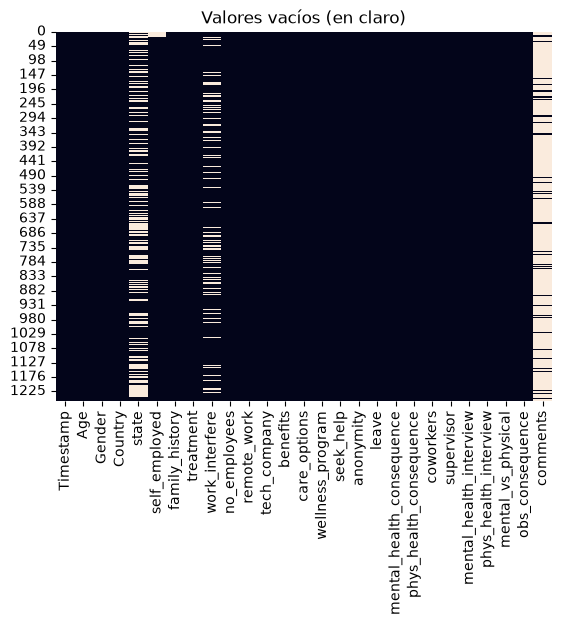

In [15]:
sns.heatmap(df.isna(), cbar=False)
plt.title("Valores vacíos (en claro)")
plt.show()

Qué vemos: los vacíos de `self_employed` están todos juntos arriba, en las primeras filas. Probablemente esa pregunta se añadió a la encuesta después de empezar.

Ahora comprobamos la causa de cada hueco: las filas vacías de `self_employed`, el país de las personas sin `state` y la relación entre `work_interfere` y `treatment`.

In [17]:
df[df["self_employed"].isna()].index.tolist()

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]

In [18]:
df[df["state"].isna()]["Country"].value_counts().head()

Country
United Kingdom    185
Canada             72
Germany            45
Netherlands        27
Ireland            27
Name: count, dtype: int64

In [19]:
pd.crosstab(df["treatment"], df["work_interfere"].isna())

work_interfere,False,True
treatment,,
No,362,260
Yes,633,4


Qué vemos: los vacíos tienen una causa, no son errores al azar.

- `comments` es texto libre y opcional.
- `state` solo se pregunta a las personas de Estados Unidos; casi todas las filas vacías son de otros países.
- `work_interfere` está vacía casi siempre (260 de 264) en las personas que no han buscado tratamiento, porque la pregunta solo tiene sentido si hay un problema de salud mental.
- `self_employed` está vacía solo en las 18 primeras filas.

#### Decisión sobre los valores vacíos

| Columna | % vacío | Decisión | Razón |
|---|---|---|---|
| `comments` | 87.0 | Eliminar la columna | Es texto libre y casi vacío; no sirve para los gráficos. |
| `state` | 40.9 | Eliminar la columna | Solo existe para Estados Unidos. Comparamos entre países, no entre estados. |
| `work_interfere` | 21.0 | Mantener y rellenar con `No aplica` | Es la única columna que mide si el problema afecta al trabajo. No se eliminan filas porque los vacíos no son al azar y se perdería el 42 % de las personas sin tratamiento. |
| `self_employed` | 1.4 | Mantener y rellenar con `Desconocido` | Son solo 18 filas. No sabemos qué habrían respondido, así que no inventamos una respuesta. |

Estas decisiones se aplican en la sección 6.2.

### 5.2 Duplicados

Objetivo: comprobar si hay respuestas repetidas, que contarían dos veces en el análisis.

In [16]:
df.duplicated().sum()

np.int64(0)

Qué vemos: hay 0 filas duplicadas; cada fila es una respuesta distinta.

Decisión: no hace falta hacer nada.

### 5.3 Edades imposibles

Objetivo: decidir qué hacer con los valores absurdos de `Age` que vimos en la sección 4.2.

Qué vemos: hay edades imposibles (-1726, -29, -1, 329 y 99999999999) y edades poco creíbles para una encuesta de trabajo (5, 8 y 11). En total son 8 filas.

#### Decisión sobre `Age`

Solo consideramos válidas las edades entre 18 y 80 años. Las demás pasan a vacío (NaN), pero conservamos la fila porque el resto de sus respuestas sigue siendo útil. No inventamos una edad que no conocemos.

Esta decisión se aplica en la sección 6.3.

### 5.4 Género escrito de muchas formas

Objetivo: entender las 49 escrituras distintas de `Gender` y decidir cómo agruparlas sin perder información.

In [36]:
df["Gender"].value_counts().to_string()

'Gender\nMale                                              615\nmale                                              206\nFemale                                            121\nM                                                 116\nfemale                                             62\nF                                                  38\nm                                                  34\nf                                                  15\nMake                                                4\nWoman                                               3\nMale                                                3\nCis Male                                            2\nFemale                                              2\nMan                                                 2\nFemale (trans)                                      2\nMale-ish                                            1\nmaile                                               1\nTrans-female                                        1\nC

Qué vemos: casi todas las respuestas son variantes de `Male` o `Female` (mayúsculas, abreviaturas como `M` y `F`, faltas de ortografía y espacios al final). Después hay respuestas únicas: identidades trans, no binarias o queer, y algunas que no son un género (`Nah`, `All`, `p`).

#### Decisión sobre `Gender`

Clasificamos a cada persona según lo que escribió, sin adivinar por ella.

| Respuestas | Qué hacemos |
|---|---|
| Variantes de hombre (`M`, `male`, `Make`, `maile`, `cis male`...) y las dudosas que contienen la palabra male (`Male-ish`, `Guy (-ish)`...) | `Male` en `Gender` |
| Variantes de mujer (`F`, `woman`, `femail`, `cis female`...) | `Female` en `Gender` |
| Respuestas que no son un género (`Nah`, `All`, `p`, `A little about you`) | NaN en `Gender` |
| Identidades trans, no binarias, queer, fluid, agender, etc. (14 personas) | Se dejan tal como están en `Gender` |

Además creamos una columna nueva, `identities`, con tres valores: `Male`, `Female` y `Trans / non-binary / other`. El tercer grupo reúne a las mujeres y hombres trans y a las identidades no binarias.

Límite: el tercer grupo tiene solo 14 personas sobre 1259, así que sus resultados son orientativos, no concluyentes.

Estas decisiones se aplican en la sección 6.4.

## 6. Limpieza de los datos

Aquí aplicamos las decisiones de la sección 5, siempre sobre la copia `df_clean`.

### 6.1 Copia del dataset

Objetivo: crear una copia del dataset para limpiar sin tocar los datos originales.

In [20]:
df_clean = df.copy()

In [21]:
df_clean.shape

(1259, 27)

In [22]:
df_clean is df

False

Qué hicimos: `df.copy()` crea un objeto nuevo e independiente (`.copy()` duplica los datos; `df_clean = df` solo daría otro nombre al mismo objeto).

Verificación: `df_clean` tiene la misma forma que `df` (1259 filas y 27 columnas) y `df_clean is df` da `False`, así que son dos objetos distintos.

Trabajamos con esta copia para no perder los datos originales y poder comparar antes y después.

### 6.2 Columnas y valores vacíos

Objetivo: aplicar las decisiones de la sección 5.1.

- `comments` y `state`: se eliminan (texto libre casi vacío; `state` solo existe para EE. UU.).
- `work_interfere`: se rellena con `No aplica` (los vacíos son sobre todo personas sin tratamiento).
- `self_employed`: se rellena con `Desconocido` (solo 18 filas y no inventamos la respuesta).

In [23]:
df_clean = df_clean.drop(columns=["comments", "state"])

In [24]:
df_clean.shape

(1259, 25)

In [25]:
df_clean["work_interfere"] = df_clean["work_interfere"].fillna("No aplica")

In [26]:
df_clean["self_employed"] = df_clean["self_employed"].fillna("Desconocido")

In [27]:
df_clean.isna().sum().sum()

np.int64(0)

In [29]:
df.shape

(1259, 27)

Qué hicimos: borramos las columnas `comments` y `state`, y rellenamos los vacíos de `work_interfere` con `No aplica` y los de `self_employed` con `Desconocido`.

Verificación: `df_clean` tiene ahora 25 columnas y ya no quedan valores vacíos (la suma es 0). `df` sigue con sus 27 columnas, sin cambios.

### 6.3 Edades

Objetivo: aplicar la decisión de la sección 5.3 (solo valen las edades entre 18 y 80 años). Primero contamos y miramos las filas afectadas, y después las pasamos a NaN.

In [30]:
mask = (df_clean["Age"] < 18) | (df_clean["Age"] > 80)
mask.sum()

np.int64(8)

In [31]:
df_clean.loc[mask, "Age"].sort_values()

715           -1726
143             -29
1127             -1
734               5
989               8
1090             11
364             329
390     99999999999
Name: Age, dtype: int64

In [32]:
df_clean["Age"] = df_clean["Age"].mask(mask)

In [33]:
df_clean["Age"].isna().sum()

np.int64(8)

In [34]:
df_clean["Age"].describe()

count    1251.000000
mean       32.076739
std         7.288272
min        18.000000
25%        27.000000
50%        31.000000
75%        36.000000
max        72.000000
Name: Age, dtype: float64

Verificación:

- `count` ahora está en 1251, lo que confirma los 8 NaN.
- `min` es 18 y `max` es 72: los valores imposibles ya no aparecen (pasaron a NaN).
- La media es 32,1 en lugar de 7,9e+07: la limpieza corrigió los outliers. La mediana es 31.
- `Age` cambió a `float64`, lo que permite tener NaN.

### 6.4 Género e `identities`

Objetivo: aplicar la decisión de la sección 5.4. Primero limpiamos `Gender` y después creamos la columna `identities`.

Primero preparamos las listas. `g` es `Gender` sin espacios y en minúsculas, para comparar sin que importen mayúsculas ni espacios. `male`, `female` e `invalid` contienen las escrituras que reconocemos (erratas, variantes `cis` y respuestas dudosas que contienen la palabra male).

In [41]:
g = df_clean["Gender"].str.strip().str.lower()
male = ["male", "m", "make", "maile", "mal", "msle", "mail", "malr", "man",
        "cis male", "male (cis)", "cis man",
        "male-ish", "guy (-ish) ^_^", "something kinda male?",
        "ostensibly male, unsure what that really means"]
female = ["female", "f", "woman", "femake", "femail",
          "cis female", "female (cis)", "cis-female/femme"]
invalid = ["nah", "all", "p", "a little about you"]

Ahora aplicamos las listas sobre `Gender`. Las respuestas que no son un género (`Nah`, `All`, `p`, `A little about you`) pasan a NaN. Lo que no está en ninguna lista (trans, no binario, fluido, queer, etc.) queda tal como lo escribió la persona.

In [42]:
df_clean.loc[g.isin(male), "Gender"] = "Male"
df_clean.loc[g.isin(female), "Gender"] = "Female"
df_clean.loc[g.isin(invalid), "Gender"] = pd.NA

In [43]:
df_clean["Gender"].value_counts(dropna=False)

Gender
Male                        994
Female                      247
NaN                           4
Female (trans)                2
Trans-female                  1
queer/she/they                1
non-binary                    1
Enby                          1
fluid                         1
Genderqueer                   1
Androgyne                     1
Agender                       1
male leaning androgynous      1
Trans woman                   1
Neuter                        1
queer                         1
Name: count, dtype: int64

#### Nueva columna `identities`

Creamos `identities` con 3 grupos: `Male`, `Female` y `Trans / non-binary / other`. Empieza con el tercer grupo para todos y luego se sobrescribe con `Male` y `Female` según `Gender`; donde `Gender` es NaN, `identities` también.

In [44]:
df_clean["identities"] = "Trans / non-binary / other"
df_clean.loc[df_clean["Gender"] == "Male", "identities"] = "Male"
df_clean.loc[df_clean["Gender"] == "Female", "identities"] = "Female"
df_clean.loc[df_clean["Gender"].isna(), "identities"] = pd.NA

In [45]:
df_clean["identities"].value_counts(dropna=False)

identities
Male                          994
Female                        247
Trans / non-binary / other     14
NaN                             4
Name: count, dtype: int64

In [46]:
df_clean["identities"].isna().sum()

np.int64(4)

Qué hicimos: limpiamos `Gender` (erratas y variantes `cis` agrupadas en `Male` o `Female`, respuestas no válidas a NaN) y creamos `identities` con 3 grupos, como pidió la profesora. `Gender` se mantiene para el detalle.

Verificación: `Male` 994 + `Female` 247 + `Trans / non-binary / other` 14 + NaN 4 = 1259 filas, y `isna().sum()` da 4.

Limitación: el tercer grupo reúne a personas trans, no binarias y otras identidades por una decisión práctica, no porque no sean mujeres u hombres. Con solo 14 respuestas, sus resultados serán orientativos.

### 6.5 Fechas (`Timestamp`)

_Pendiente._

### 6.6 Guardar el dataset limpio

_Pendiente._

## 7. Análisis

### 7.1 Análisis univariado

_Pendiente._

### 7.2 Análisis bivariado

_Pendiente._

## 8. Respuesta a las preguntas de partida

_Pendiente._

## 9. Conclusiones y límites

_Pendiente._